In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [15]:
class TwoLayersPerceptron:
    def __init__(self, input_size, hidden_size, output_size):
        np.random.seed(42)   #Le meto una semilla fija para obtener siempre los mismos resultados

        #Generamos de forma aleatoria las matrices de pesos sinápticos y los sesgos, para capa oculta y para salida
        self.W1 = np.random.randn(input_size, hidden_size)    # Input to hidden
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size)   # Hidden to output
        self.b2 = np.zeros((1, output_size))

        self.historial_errores = []

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def _sigmoid_deriv(self, x):
        return x * (1 - x)

    def predict(self, X):
        z1 = np.dot(X, self.W1) + self.b1
        a1 = self._sigmoid(z1)

        #Cambio a regresión quitando la aplicacion de la función sigmoide
        z2 = np.dot(a1, self.W2) + self.b2
        output = z2
        return output

    def fit(self, X, y, learning_rate=0.01, epochs=100):
        self.historial_errores = []  #Reinicio el historial de errores en cada entreno
        N = X.shape[0]

        for _ in range(epochs):
            # Forward pass
            z1 = np.dot(X, self.W1) + self.b1
            a1 = self._sigmoid(z1)
            z2 = np.dot(a1, self.W2) + self.b2
            output = z2

            #Backward pass
            error = y - output #Calculo el error con respecto a la exacta
            self.historial_errores.append(np.mean(np.square(error))) # Añadimos el error cuadrático medio
            d_output = -2 * error / N   #Meto la derivada del ECM

            error_hidden = d_output.dot(self.W2.T)
            d_hidden = error_hidden * self._sigmoid_deriv(a1)

            # Update weights and biases
            self.W2 -= a1.T.dot(d_output) * learning_rate
            self.b2 -= np.sum(d_output, axis=0, keepdims=True) * learning_rate
            self.W1 -= X.T.dot(d_hidden) * learning_rate
            self.b1 -= np.sum(d_hidden, axis=0, keepdims=True) * learning_rate


    # Función extra para graficar cómo cae el error
    def plot_loss(self):
        plt.plot(self.historial_errores, color='blue', linewidth=2)
        plt.title('Evolución del error durante el entrenamiento')
        plt.xlabel('Épocas')
        plt.ylabel('Error')
        plt.ylim(0, 1)
        plt.grid(True)
        plt.show()

Columnas del dataset: Index(['X', 'Y'], dtype='object')


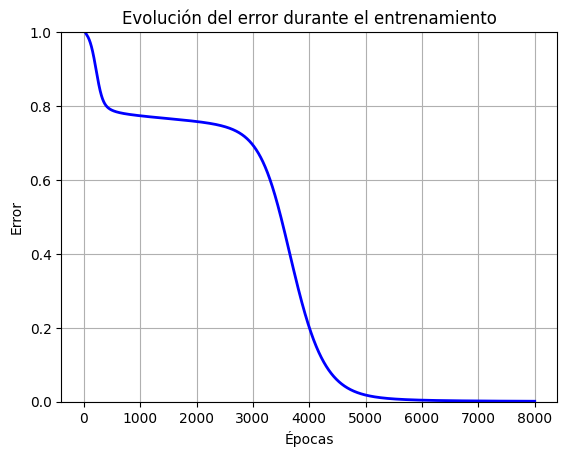

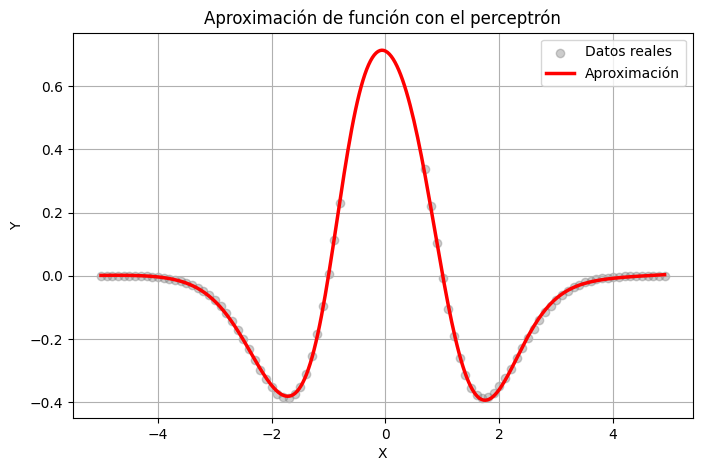

In [18]:
#Probamos con los datos proporcionados.

df = pd.read_parquet('/data_train.parquet')
print("Columnas del dataset:", df.columns)

#Creo los conjuntos de entrenamiento
X_train = df['X'].values.reshape(-1, 1)
y_train = df['Y'].values.reshape(-1, 1)

#Normalizo los datos de entrenamiento para que la sigmoide no explote
X_mean, X_std = X_train.mean(), X_train.std()
y_mean, y_std = y_train.mean(), y_train.std()

X_train_norm = (X_train - X_mean) / X_std
y_train_norm = (y_train - y_mean) / y_std

#Creo el perceptrón
modelo = TwoLayersPerceptron(input_size=1, hidden_size=9, output_size=1)
modelo.fit(X_train_norm, y_train_norm, learning_rate=0.2, epochs=8000)

#Compruebo como avanza el error en cada epoca
modelo.plot_loss()

#Genero datos para el test y los normalizo
x_test = np.linspace(X_train.min(), X_train.max(), 300).reshape(-1, 1)
x_test_norm = (x_test - X_mean) / X_std

#Predigo con el modelo y desnormalizo para pintarlo
y_pred_norm = modelo.predict(x_test_norm)
y_pred = (y_pred_norm * y_std) + y_mean

#Grafica
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='gray', alpha=0.4, label='Datos reales')
plt.plot(x_test, y_pred, color='red', linewidth=2.5, label='Aproximación')
plt.title('Aproximación de función con el perceptrón')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

